In [1]:
"""候選「PJM 電網負載與氣象」的篩選用檢視（notebook 版）。

與 `pjm-demand-weather.py` 內容相同，只改為 `# %%` 分格以便轉 notebook：

    jupytext --to notebook scripts/explore/nb_pjm_demand_weather.py

僅供判斷此候選是否適合作為選題，非分析結果。
範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、唯一值數、
描述統計、單變數分布、時間序列折線圖。相關係數另行標註。

**不配適任何模型。** 本候選的核心賣點是「氣象效應與資料中心結構性成長
的分離」，那需要迴歸，屬禁止範圍。這裡只驗證該賣點的前提是否成立。
"""

'候選「PJM 電網負載與氣象」的篩選用檢視（notebook 版）。\n\n與 `pjm-demand-weather.py` 內容相同，只改為 `# %%` 分格以便轉 notebook：\n\n    jupytext --to notebook scripts/explore/nb_pjm_demand_weather.py\n\n僅供判斷此候選是否適合作為選題，非分析結果。\n範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、唯一值數、\n描述統計、單變數分布、時間序列折線圖。相關係數另行標註。\n\n**不配適任何模型。** 本候選的核心賣點是「氣象效應與資料中心結構性成長\n的分離」，那需要迴歸，屬禁止範圍。這裡只驗證該賣點的前提是否成立。\n'

# PJM 電網負載與氣象：篩選檢視

資料源：https://www.kaggle.com/datasets/arimancy/pjm-hourly-demand-weather

核心賣點是「氣象效應與資料中心結構性成長的分離」。那需要迴歸，
不在篩選階段的允許範圍內，所以這裡只驗證該賣點的**四個前提**：

1. 時間軸是否真如作者所述無缺漏
2. 品質旗標是否存在且有作用
3. 負載是否真有氣象解釋不了的結構性成長
4. 氣溫與負載是否呈非線性（U 形）關係

分離本身留待正式分析階段。

In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import polars as pl

for family in ("Noto Sans CJK TC", "Noto Sans CJK JP", "WenQuanYi Zen Hei"):
    if any(family in f.name for f in matplotlib.font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = family
        break
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

SRC = ROOT / "data" / "raw" / "pjm-demand-weather" / "pjm_demand_weather_hourly_v1.parquet"
FIGS = ROOT / "outputs" / "figures" / "screening"


def show(df: pl.DataFrame, rows: int = -1) -> None:
    with pl.Config(tbl_rows=rows, tbl_cols=-1, tbl_width_chars=200):
        print(df)


df = pl.read_parquet(SRC)
print(f"資料檔：{SRC.name}（{SRC.stat().st_size / 1e6:.1f} MB）")
print(f"{df.height:,} 列 × {df.width} 欄")

資料檔：pjm_demand_weather_hourly_v1.parquet（10.9 MB）
97,850 列 × 44 欄


## 1. 基本結構與各欄缺失率

44 欄分六群：時間、負載、逐點氣溫、人口加權氣象、日曆、度數特徵。
另有一組氣象溯源欄位。

In [3]:
rows = []
for col in df.columns:
    s = df[col]
    rows.append({
        "欄位": col,
        "型別": str(s.dtype).replace("Datetime(time_unit='us', time_zone=", "tz("),
        "缺失率": s.null_count() / df.height,
        "唯一值": s.n_unique(),
    })
show(pl.DataFrame(rows))

shape: (44, 4)
┌─────────────────────────────────┬────────────────────────┬──────────┬────────┐
│ 欄位                            ┆ 型別                   ┆ 缺失率   ┆ 唯一值 │
│ ---                             ┆ ---                    ┆ ---      ┆ ---    │
│ str                             ┆ str                    ┆ f64      ┆ i64    │
╞═════════════════════════════════╪════════════════════════╪══════════╪════════╡
│ datetime_utc                    ┆ tz('UTC')              ┆ 0.0      ┆ 97850  │
│ datetime_local                  ┆ tz('America/New_York') ┆ 0.0      ┆ 97850  │
│ demand_mwh                      ┆ Float64                ┆ 0.0      ┆ 97844  │
│ demand_reported_mwh             ┆ Float64                ┆ 0.002473 ┆ 47549  │
│ demand_imputed_pudl_mwh         ┆ Float64                ┆ 0.006888 ┆ 97177  │
│ demand_imputed_pudl_mwh_imputa… ┆ String                 ┆ 0.997149 ┆ 7      │
│ demand_is_imputed               ┆ Boolean                ┆ 0.0      ┆ 2      │
│ demand_source        

有缺失的欄位集中在兩處：氣象各欄（ERA5 再分析延遲的尾端）與
`demand_imputed_pudl_mwh`（PUDL 尚未覆蓋的 API 尾端）。

`demand_imputed_pudl_mwh_imputation_code` 缺失 99.71% 是**結構性**的——
只有實際補值的那些列才會填這一欄。

**`demand_mwh`（正準負載）零缺失。**

## 2. 時間軸完整性（賣點一）

作者宣稱 UTC 軸上連續、唯一、無間隙。逐項驗證。

In [4]:
ts = df["datetime_utc"]
start, end = ts.min(), ts.max()
span_hours = int((end - start).total_seconds() // 3600) + 1

print(f"起訖　　　 {start} 至 {end}")
print(f"實際列數　 {df.height:,}")
print(f"應有小時數 {span_hours:,}（依起訖推算）")
print(f"缺漏　　　 {span_hours - df.height:,} 小時")
print(f"重複時間戳 {df.height - ts.n_unique():,} 個")

起訖　　　 2015-07-01 05:00:00+00:00 至 2026-08-29 06:00:00+00:00
實際列數　 97,850
應有小時數 97,850（依起訖推算）
缺漏　　　 0 小時
重複時間戳 0 個


In [5]:
# 相鄰時間戳的間隔分布。只有一種值才代表真的無缺漏。
gaps = (
    df.select(pl.col("datetime_utc").sort().diff().alias("間隔"))
    .drop_nulls()
    .group_by("間隔")
    .agg(pl.len().alias("次數"))
    .sort("次數", descending=True)
)
show(gaps)
print("\n只有 1h 這一種間隔，沒有第二種值。時間軸確實連續無缺漏。")
print("這是目前檢視過的候選中唯一做到這點的。")

shape: (1, 2)
┌──────────────┬───────┐
│ 間隔         ┆ 次數  │
│ ---          ┆ ---   │
│ duration[μs] ┆ u32   │
╞══════════════╪═══════╡
│ 1h           ┆ 97849 │
└──────────────┴───────┘

只有 1h 這一種間隔，沒有第二種值。時間軸確實連續無缺漏。
這是目前檢視過的候選中唯一做到這點的。


## 3. 品質旗標（賣點二）

旗標若全為 False 就等於沒有。逐個確認實際標出了東西。

In [6]:
FLAGS = [
    "demand_is_imputed",
    "temp_is_missing",
    "temp_is_imputed",
    "weather_is_preliminary",
    "is_dst_transition_day",
    "degree_day_is_partial",
    "is_weekend",
    "is_holiday_statutory",
    "is_holiday_observed",
]

flag_rows = []
for flag in FLAGS:
    n_true = df[flag].sum()
    flag_rows.append({
        "旗標": flag,
        "True 筆數": n_true,
        "佔比": n_true / df.height,
    })
show(pl.DataFrame(flag_rows))

shape: (9, 3)
┌────────────────────────┬───────────┬──────────┐
│ 旗標                   ┆ True 筆數 ┆ 佔比     │
│ ---                    ┆ ---       ┆ ---      │
│ str                    ┆ i64       ┆ f64      │
╞════════════════════════╪═══════════╪══════════╡
│ demand_is_imputed      ┆ 279       ┆ 0.002851 │
│ temp_is_missing        ┆ 127       ┆ 0.001298 │
│ temp_is_imputed        ┆ 0         ┆ 0.0      │
│ weather_is_preliminary ┆ 127       ┆ 0.001298 │
│ is_dst_transition_day  ┆ 528       ┆ 0.005396 │
│ degree_day_is_partial  ┆ 26        ┆ 0.000266 │
│ is_weekend             ┆ 27939     ┆ 0.285529 │
│ is_holiday_statutory   ┆ 2808      ┆ 0.028697 │
│ is_holiday_observed    ┆ 3168      ┆ 0.032376 │
└────────────────────────┴───────────┴──────────┘


**`temp_is_imputed` 全期為 0。**

字典說它標記「3 小時以內的內部間隙以線性內插填補」，但本檔一次都沒用到
——127 個缺值全是尾端邊緣間隙，依規則不插補。

這表示**氣象欄位沒有任何插補值**，是好事，但該旗標在本檔無資訊。

In [7]:
# demand_source：哪些列是清理過的骨幹、哪些是未篩檢的初步尾端。
show(
    df.group_by("demand_source")
    .agg(
        pl.len().alias("筆數"),
        pl.col("datetime_utc").min().alias("最早"),
        pl.col("datetime_utc").max().alias("最晚"),
    )
    .sort("筆數", descending=True)
)
print("\neia_api 是未經異常篩檢的初步值，每次 rebuild 會被 PUDL 清理值取代。")

shape: (2, 4)
┌───────────────┬───────┬─────────────────────────┬─────────────────────────┐
│ demand_source ┆ 筆數  ┆ 最早                    ┆ 最晚                    │
│ ---           ┆ ---   ┆ ---                     ┆ ---                     │
│ str           ┆ u32   ┆ datetime[μs, UTC]       ┆ datetime[μs, UTC]       │
╞═══════════════╪═══════╪═════════════════════════╪═════════════════════════╡
│ pudl          ┆ 97176 ┆ 2015-07-01 05:00:00 UTC ┆ 2026-08-01 04:00:00 UTC │
│ eia_api       ┆ 674   ┆ 2026-08-01 05:00:00 UTC ┆ 2026-08-29 06:00:00 UTC │
└───────────────┴───────┴─────────────────────────┴─────────────────────────┘

eia_api 是未經異常篩檢的初步值，每次 rebuild 會被 PUDL 清理值取代。


In [8]:
# PUDL 的補值原因碼。有這個才能做敏感度分析。
show(
    df.filter(pl.col("demand_imputed_pudl_mwh_imputation_code").is_not_null())
    .group_by("demand_imputed_pudl_mwh_imputation_code")
    .agg(pl.len().alias("筆數"))
    .sort("筆數", descending=True)
)

shape: (6, 2)
┌─────────────────────────────────┬──────┐
│ demand_imputed_pudl_mwh_imputa… ┆ 筆數 │
│ ---                             ┆ ---  │
│ str                             ┆ u32  │
╞═════════════════════════════════╪══════╡
│ missing_value                   ┆ 242  │
│ anomalous_region                ┆ 21   │
│ double_delta                    ┆ 6    │
│ local_outlier_high              ┆ 6    │
│ global_outlier                  ┆ 3    │
│ local_outlier_low               ┆ 1    │
└─────────────────────────────────┴──────┘


## 4. 負載的結構性成長（賣點三）

只看描述統計，不做任何分解——分解需要迴歸。

In [9]:
yearly = (
    df.with_columns(pl.col("datetime_local").dt.year().alias("年"))
    .group_by("年")
    .agg(
        pl.len().alias("小時數"),
        pl.col("demand_mwh").mean().round(0).alias("平均MWh"),
        pl.col("demand_mwh").max().round(0).alias("尖峰MWh"),
        pl.col("temp_pop_wt_c").mean().round(2).alias("平均氣溫C"),
    )
    .sort("年")
)
show(yearly)
print("\n2015 與 2026 為部分年度。")
print("2016-2023 在 87,695-93,763 間震盪、看不出趨勢，2024 起明顯抬升。")
print("尖峰也連兩年刷新十年紀錄（2025 年 160,560、2026 年 162,648）。")

shape: (12, 5)
┌──────┬────────┬──────────┬──────────┬───────────┐
│ 年   ┆ 小時數 ┆ 平均MWh  ┆ 尖峰MWh  ┆ 平均氣溫C │
│ ---  ┆ ---    ┆ ---      ┆ ---      ┆ ---       │
│ i32  ┆ u32    ┆ f64      ┆ f64      ┆ f64       │
╞══════╪════════╪══════════╪══════════╪═══════════╡
│ 2015 ┆ 4416   ┆ 89904.0  ┆ 144302.0 ┆ 16.83     │
│ 2016 ┆ 8784   ┆ 91889.0  ┆ 152890.0 ┆ 13.24     │
│ 2017 ┆ 8760   ┆ 89959.0  ┆ 146553.0 ┆ 13.16     │
│ 2018 ┆ 8760   ┆ 93763.0  ┆ 151479.0 ┆ 12.6      │
│ 2019 ┆ 8760   ┆ 91353.0  ┆ 152315.0 ┆ 12.71     │
│ 2020 ┆ 8784   ┆ 87695.0  ┆ 145428.0 ┆ 13.31     │
│ 2021 ┆ 8760   ┆ 90889.0  ┆ 149590.0 ┆ 13.4      │
│ 2022 ┆ 8760   ┆ 92485.0  ┆ 148528.0 ┆ 12.77     │
│ 2023 ┆ 8760   ┆ 89595.0  ┆ 147605.0 ┆ 13.59     │
│ 2024 ┆ 8784   ┆ 92788.0  ┆ 153121.0 ┆ 13.66     │
│ 2025 ┆ 8760   ┆ 96251.0  ┆ 160560.0 ┆ 12.61     │
│ 2026 ┆ 5762   ┆ 100872.0 ┆ 162648.0 ┆ 13.38     │
└──────┴────────┴──────────┴──────────┴───────────┘

2015 與 2026 為部分年度。
2016-2023 在 87,695-93,763 間震盪、看不出趨勢，2024 

In [10]:
# 七月同月比較。同月已控掉季節，但未控氣溫。
july = (
    df.filter(pl.col("datetime_local").dt.month() == 7)
    .with_columns(pl.col("datetime_local").dt.year().alias("年"))
    .group_by("年")
    .agg(
        pl.len().alias("小時數"),
        pl.col("demand_mwh").mean().round(0).alias("七月平均MWh"),
        pl.col("temp_pop_wt_c").mean().round(2).alias("七月平均氣溫C"),
    )
    .sort("年")
)
show(july)

shape: (12, 4)
┌──────┬────────┬─────────────┬───────────────┐
│ 年   ┆ 小時數 ┆ 七月平均MWh ┆ 七月平均氣溫C │
│ ---  ┆ ---    ┆ ---         ┆ ---           │
│ i32  ┆ u32    ┆ f64         ┆ f64           │
╞══════╪════════╪═════════════╪═══════════════╡
│ 2015 ┆ 743    ┆ 102251.0    ┆ 24.16         │
│ 2016 ┆ 744    ┆ 107467.0    ┆ 25.41         │
│ 2017 ┆ 744    ┆ 103833.0    ┆ 24.62         │
│ 2018 ┆ 744    ┆ 104698.0    ┆ 24.74         │
│ 2019 ┆ 744    ┆ 109324.0    ┆ 25.72         │
│ 2020 ┆ 744    ┆ 110035.0    ┆ 26.38         │
│ 2021 ┆ 744    ┆ 104074.0    ┆ 24.45         │
│ 2022 ┆ 744    ┆ 106776.0    ┆ 25.48         │
│ 2023 ┆ 744    ┆ 106218.0    ┆ 24.98         │
│ 2024 ┆ 744    ┆ 109807.0    ┆ 25.11         │
│ 2025 ┆ 744    ┆ 116188.0    ┆ 25.9          │
│ 2026 ┆ 744    ┆ 114957.0    ┆ 25.15         │
└──────┴────────┴─────────────┴───────────────┘


### 作者 caveat 的「兩年 10%」不可直接引用

字典 caveats 寫：

> Mean July demand ran 109,807 MWh in 2024, 116,188 in 2025, and 120,628
> in the partial July 2026 (through the 19th), about 10 percent in two years.

**第三個數字是部分月**——他建置時七月還沒過完。本檔的 2026 年七月已完整
（744 小時）。以同口徑重算看看。

In [11]:
full_july = (
    df.filter(pl.col("datetime_local").dt.month() == 7)
    .with_columns(pl.col("datetime_local").dt.year().alias("年"))
    .group_by("年")
    .agg(pl.col("demand_mwh").mean().round(0).alias("完整七月"))
)
partial_july = (
    df.filter(
        (pl.col("datetime_local").dt.month() == 7)
        & (pl.col("datetime_local").dt.day() <= 19)
    )
    .with_columns(pl.col("datetime_local").dt.year().alias("年"))
    .group_by("年")
    .agg(pl.col("demand_mwh").mean().round(0).alias("七月1-19日"))
)
show(
    full_july.join(partial_july, on="年")
    .sort("年")
    .filter(pl.col("年") >= 2024)
    .select("年", "七月1-19日", "完整七月")
)

print("""
1-19 日口徑 2024→2026 為 +7.1%，非 10%。
而完整七月的 2026（114,957）反而低於 2025（116,188）。

這不是作者造假——資料每次 rebuild 尾端會推進，他寫 caveat 時 2026 年
七月尚未結束。但**那個 10% 不可直接引用**，要自己按當前檔案重算，
且部分月與完整月的口徑不可混用。

這類會滾動更新的資料集都要注意這點。""")

shape: (3, 3)
┌──────┬────────────┬──────────┐
│ 年   ┆ 七月1-19日 ┆ 完整七月 │
│ ---  ┆ ---        ┆ ---      │
│ i32  ┆ f64        ┆ f64      │
╞══════╪════════════╪══════════╡
│ 2024 ┆ 111981.0   ┆ 109807.0 │
│ 2025 ┆ 114811.0   ┆ 116188.0 │
│ 2026 ┆ 119961.0   ┆ 114957.0 │
└──────┴────────────┴──────────┘

1-19 日口徑 2024→2026 為 +7.1%，非 10%。
而完整七月的 2026（114,957）反而低於 2025（116,188）。

這不是作者造假——資料每次 rebuild 尾端會推進，他寫 caveat 時 2026 年
七月尚未結束。但**那個 10% 不可直接引用**，要自己按當前檔案重算，
且部分月與完整月的口徑不可混用。

這類會滾動更新的資料集都要注意這點。


## 5. 氣溫與負載的關係（賣點四）

分箱平均只用於確認非線性形狀存在，**不是反應函數的估計**。

In [12]:
binned = (
    df.drop_nulls(["temp_pop_wt_c", "demand_mwh"])
    .with_columns(
        (pl.col("temp_pop_wt_c") / 5).floor().mul(5).cast(pl.Int32).alias("氣溫組")
    )
    .group_by("氣溫組")
    .agg(
        pl.len().alias("小時數"),
        pl.col("demand_mwh").mean().round(0).alias("平均MWh"),
    )
    .sort("氣溫組")
)
show(binned)
print("\n每 5°C 一組。谷底在 10-15°C，冷熱兩端皆升 = U 形。")
print("非線性明確，需要平滑項或分段迴歸，線性項不夠。")
print("**分箱平均僅供確認形狀，非反應函數的估計。**")

shape: (12, 3)
┌────────┬────────┬──────────┐
│ 氣溫組 ┆ 小時數 ┆ 平均MWh  │
│ ---    ┆ ---    ┆ ---      │
│ i32    ┆ u32    ┆ f64      │
╞════════╪════════╪══════════╡
│ -20    ┆ 19     ┆ 127307.0 │
│ -15    ┆ 445    ┆ 123193.0 │
│ -10    ┆ 2031   ┆ 113229.0 │
│ -5     ┆ 6590   ┆ 101893.0 │
│ 0      ┆ 13880  ┆ 92882.0  │
│ 5      ┆ 15552  ┆ 84121.0  │
│ 10     ┆ 14080  ┆ 78435.0  │
│ 15     ┆ 14629  ┆ 80394.0  │
│ 20     ┆ 18644  ┆ 94138.0  │
│ 25     ┆ 10447  ┆ 116551.0 │
│ 30     ┆ 1399   ┆ 136588.0 │
│ 35     ┆ 7      ┆ 156983.0 │
└────────┴────────┴──────────┘

每 5°C 一組。谷底在 10-15°C，冷熱兩端皆升 = U 形。
非線性明確，需要平滑項或分段迴歸，線性項不夠。
**分箱平均僅供確認形狀，非反應函數的估計。**


In [13]:
# 相關係數矩陣。僅供篩選，非分析結果。
NUMERIC = [
    "demand_mwh", "temp_pop_wt_c", "apparent_temp_pop_wt_c",
    "hdh_65", "cdh_65", "shortwave_radiation_pop_wt_wm2",
    "cloud_cover_pop_wt_pct", "snowfall_pop_wt_cm",
]
sub = df.select(NUMERIC).drop_nulls()
corr = pl.DataFrame({
    "變數": NUMERIC,
    **{c: [sub.select(pl.corr(a, c)).item() for a in NUMERIC] for c in NUMERIC},
})
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=220, float_precision=3):
    print(corr)

shape: (8, 9)
┌────────────────────────────────┬────────────┬───────────────┬────────────────────────┬────────┬────────┬────────────────────────────────┬────────────────────────┬────────────────────┐
│ 變數                           ┆ demand_mwh ┆ temp_pop_wt_c ┆ apparent_temp_pop_wt_c ┆ hdh_65 ┆ cdh_65 ┆ shortwave_radiation_pop_wt_wm2 ┆ cloud_cover_pop_wt_pct ┆ snowfall_pop_wt_cm │
│ ---                            ┆ ---        ┆ ---           ┆ ---                    ┆ ---    ┆ ---    ┆ ---                            ┆ ---                    ┆ ---                │
│ str                            ┆ f64        ┆ f64           ┆ f64                    ┆ f64    ┆ f64    ┆ f64                            ┆ f64                    ┆ f64                │
╞════════════════════════════════╪════════════╪═══════════════╪════════════════════════╪════════╪════════╪════════════════════════════════╪════════════════════════╪════════════════════╡
│ demand_mwh                     ┆ 1.000      ┆ 0.191     

三個判讀重點：

- **負載與氣溫的線性相關只有 0.191**——U 形關係讓線性係數嚴重低估。
  換成冷卻度時 `cdh_65` 就到 0.665
- **夏季訊號遠強於冬季**：`cdh_65` 0.665 對比 `hdh_65` 0.041
- **氣象欄位之間高度共線**：氣溫與體感溫度 0.995、與供暖度時 −0.961。
  建模時須處理

`cloud_cover_pop_wt_pct` 與負載相關 −0.000，單獨使用無訊號。

## 6. 圖

時間序列折線圖與單變數分布，皆屬篩選階段的允許範圍。

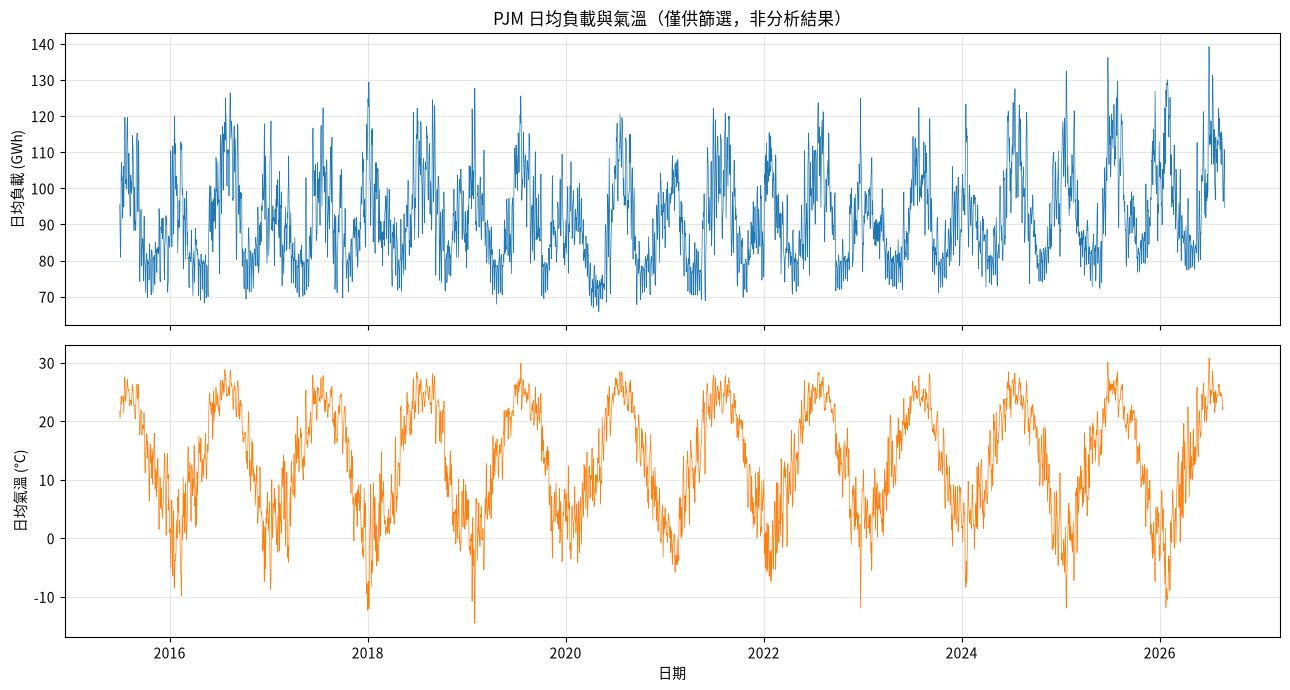

In [14]:
FIGS.mkdir(parents=True, exist_ok=True)

daily = (
    df.with_columns(pl.col("datetime_local").dt.date().alias("日"))
    .group_by("日")
    .agg(
        pl.col("demand_mwh").mean().alias("日均負載"),
        pl.col("temp_pop_wt_c").mean().alias("日均氣溫"),
    )
    .sort("日")
)

_, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(daily["日"], daily["日均負載"] / 1000, linewidth=0.5)
axes[0].set_ylabel("日均負載 (GWh)")
axes[0].set_title("PJM 日均負載與氣溫（僅供篩選，非分析結果）")
axes[1].plot(daily["日"], daily["日均氣溫"], linewidth=0.5, color="tab:orange")
axes[1].set_ylabel("日均氣溫 (°C)")
axes[1].set_xlabel("日期")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "pjm-daily-series.png", dpi=110)
plt.show()

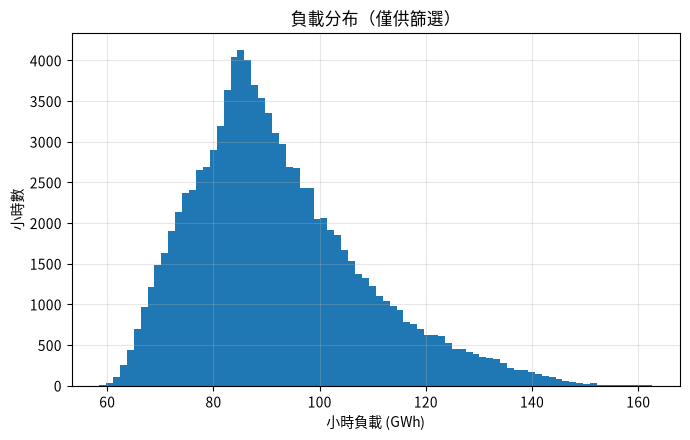

In [15]:
_, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(df["demand_mwh"].drop_nulls().to_numpy() / 1000, bins=80)
ax.set_xlabel("小時負載 (GWh)")
ax.set_ylabel("小時數")
ax.set_title("負載分布（僅供篩選）")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "pjm-demand-hist.png", dpi=110)
plt.show()

## 小結

四個前提逐項檢驗的結果：

| 前提 | 結果 |
|---|---|
| 時間軸無缺漏 | **成立**。97,850 列與推算完全一致，間隔只有 1h 一種 |
| 品質旗標有作用 | **大致成立**。僅 `temp_is_imputed` 全為 0（因為本檔沒有插補值） |
| 有結構性成長 | **成立**。2024 起抬升，尖峰連兩年刷新十年紀錄 |
| 氣溫反應非線性 | **成立**。谷底 10-15°C，兩端皆升 |

另外抓到一點：**作者 caveat 裡那個「兩年 10%」是用部分月算的，
不可直接引用。**

**以上皆為篩選，不是分析結果。** 氣象與結構成長的分離需要迴歸，
留待正式分析階段。